# <span style="color:#9947dc">HI-Small — Preprocessing on the subsample (step 3)</span>

**What this notebook is for.** It turns the **subsample** built by `02_subsample_split.py` into the
model-ready train / validation / test tables the modelling notebook uses. Every decision points to
the section of the EDA notebook (`notebooks/EDA_HI_Small_v2.ipynb`) it comes from, written **EDA A…** (full file)
or **EDA B…** (subsample).

**Which rows, which history.**

| | Comes from | Why |
|---|---|---|
| Rows the model sees, label, `weight`, train / val / test | the **subsample**, time split (`data/processed/sample/time/`) | EDA B1, B4, B19 |
| Robustness split | the **same** subsample, group split (`data/processed/sample/group/`) | EDA B4, `02_subsample_split.py group` |
| Account history behind each feature (counts, counterparties, bursts, conversion step) | the **full** joined file, only transfers **before** each row | EDA B6, B19: computed from the sample, account counts are wrong for 88.7% of rows, and wrong differently for laundering and normal rows |
| Things learned from data (FX table, caps, category levels) | the subsample's **train** split, weighted | fitted on train only |
| Hub list | the full file, train dates | a counterparty count is an account total (A8) |

So only subsample rows are processed and written out; the full file is read only as history.
`HISTORY_FROM = "sample"` (section 0) computes the history from the subsample instead — available
for comparison, but EDA B6 shows it gives the model a sampling artefact.

| | |
|---|---|
| **Input** | `data/processed/hi_small_joined.parquet` (`01_join_sql.py`) and `data/processed/sample/{time,group}/` (`02_subsample_split.py time` / `group`, built here if missing) |
| **Output** | `data/processed/preprocessed/` — `{train,val,test}_features.parquet` (row_id + 40 features + label), `{train,val,test}_meta.parquet` (weight, time, accounts, splits, ground truth), `artifacts.json`, `fx_table.csv`, `hubs.csv`, `data_dictionary.md`, `build_report.json` |
| **Check** | `src/03b_verify_preprocessing.py`, an independent re-derivation (run in section 8) |
| **Figure** | `reports/figures/03_flag_lift_train.png` |

**Order:** 1 clean → 2 attach the subsample → 3 learn on train → 4 point-in-time features →
5 fit caps and categories on train → 6 export → 7 checks → 8 independent verification.

## <span style="color:#9947dc">0. Setup</span>

Settings you may want to change:
- `BUILD_SAMPLE_IF_MISSING` — run `02_subsample_split.py` (time and group) and `02b_verify_sample.py` if the subsample folders are missing.
- `HISTORY_FROM` — `"full"` (default, EDA B6) or `"sample"`.
- `RUN_VERIFY`, `VERIFY_ROWS` — run the independent verification at the end.

The constants below are design decisions with their EDA section; they are saved in `artifacts.json`.

In [1]:
import hashlib
import json
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display


def find_root(start: Path) -> Path:
    """The aml_pipeline folder (the one holding src/), from its subfolders or from above it."""
    for p in [start, *start.parents, start / "aml_pipeline"]:
        if (p / "src" / "eda_utils.py").is_file():
            return p
    raise FileNotFoundError("open this notebook from inside the aml_pipeline folder")


ROOT = find_root(Path.cwd())

# ---------------------------------------------------------------- run settings
JOINED = ROOT / "data" / "processed" / "hi_small_joined.parquet"
SAMPLE_DIR = ROOT / "data" / "processed" / "sample"
OUT = ROOT / "data" / "processed" / "preprocessed"
REPORTS = ROOT / "reports"
BUILD_SAMPLE_IF_MISSING = True
HISTORY_FROM = "full"             # "full" (EDA B6) or "sample"
RUN_VERIFY = True
VERIFY_ROWS = 1000

# ---------------------------------------------------------------- design decisions
CUTOFF = "2022-09-11"             # EDA A3: from 11 Sept only leftover scheme rows (also dropped by 02)
SPLIT_DAYS = {                    # same days as 02_subsample_split.py time mode (EDA B4)
    "train": ("2022-09-01", "2022-09-06"),
    "val": ("2022-09-07", "2022-09-07"),
    "test": ("2022-09-08", "2022-09-10"),
}
TRAIN_END = "2022-09-07"          # hub list: full-file rows before this date
LOOKBACK_H = 48                   # fixed account-history window (section 4)
PASSTHROUGH_H = 24                # EDA B15: money forwarded within 24 h ...
PASSTHROUGH_TOL = 0.10            # ... and within 10% of what arrived
HUB_MIN_COUNTERPARTIES = 500      # EDA A8 / the sampler's hub definition
CONVERSION_REL_TOL = 1e-6         # "same amount" up to float noise (sub-cent Bitcoin too)
CAP_QUANTILE = 0.999              # counts capped at the weighted train 99.9th percentile
CATEGORY_MIN_WEIGHT = {           # levels with less weighted train volume than this -> "Other"
    "payment_format": 100, "payment_currency": 100,
    "country_from": 100, "country_to": 100, "etype_from": 100, "etype_to": 100,
}
TARGET = "Is Laundering"
ROW_KEY = ["Timestamp", "From Bank", "Account", "To Bank", "Account.1",
           "Amount Paid", "Amount Received", "Payment Format",
           "Payment Currency", "Receiving Currency"]
assert HISTORY_FROM in ("full", "sample")

pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_colwidth", 90)
PURPLE, LILAC = "#9947dc", "#c9a6ef"

### <span style="color:#9947dc">0.1 Feature list and data dictionary</span>

Fixed before any data is read, so nothing is chosen by looking at the label. The list follows
EDA B19 (rules) and B8–B17b (signals on the train split):

- **Built:** pair history (B14), sender / receiver history and bursts (B12, B13), hub flags (B16),
  amount in USD + currency change (B9, B11), countries, cross-border, cross-bank (B9, B10),
  the conversion step (B15) and payment format (B8) — the last two are **generator artefacts**, so the
  modelling notebook trains with and without them.
- **Kept although weak** (B17: weak on their own; cheap, and the report can show
  they are weak): corrected pass-through and dwell (B15), same owner (B9), owner type (B10),
  distinct counterparties (B12).
- **Not built:** hour, weekday, round / repeated amounts, account lifetime (B17b),
  "minutes since last transfer" on its own (B17b), country-to-country routes (B17b: most
  routes rest on a handful of laundering rows), bank names and account IDs (B3).

In [2]:
COUNT_FEATURES = [               # over [t - 48 h, t) unless the name says otherwise
    "snd_sent_48h", "snd_recv_48h", "rcv_recv_48h", "rcv_sent_48h",
    "snd_cpty_48h", "rcv_cpty_48h", "pair_prev_48h",
    "snd_sent_24h", "snd_sent_60m", "rcv_recv_24h", "rcv_recv_60m",
    # graph shape (EDA B16b): bursts, gather / scatter sides, 2-step paths and 3-step cycles
    "snd_cpty_6h", "rcv_cpty_6h", "snd_in_cpty_48h", "rcv_out_cpty_48h", "sg_paths_48h", "cycle3_48h",
]
TIME_FEATURES = ["snd_dwell_h", "snd_recv_usd_24h", "snd_amt_vs_mean_48h"]   # continuous (scaled in logreg)
FLAG_FEATURES = [
    "new_pair_48h", "reverse_pair_48h", "snd_quiet_48h", "rcv_quiet_48h",
    "passthrough", "conversion_before", "snd_hub", "rcv_hub",
    "cross_bank", "cross_border", "same_entity", "currency_changes", "snd_new_format_48h",
]
AMOUNT_FEATURES = ["log_amount_usd"]
CATEGORICAL_FEATURES = list(CATEGORY_MIN_WEIGHT)
FEATURES = COUNT_FEATURES + TIME_FEATURES + FLAG_FEATURES + AMOUNT_FEATURES + CATEGORICAL_FEATURES
FORMAT_FEATURES = ["payment_format", "snd_new_format_48h"]
GENERATOR_FEATURES = ["payment_format", "snd_new_format_48h", "conversion_before"]

META_COLUMNS = [
    "row_id", "Timestamp", "day", "split", "own_date_split", "group_split", "weight",
    "seed_from", "seed_to", "scheme_moved", "scheme_truncated", "history_complete",
    "acct_from", "acct_to", "Payment Format", "amount_usd",
    "explained", "Attempt ID", "Pattern Type",          # ground truth: evaluation only
    "net_48h", "net_24h", "net_60m",                    # network volume: drift diagnostics only
]
LEAK_COLUMNS = [                  # EDA B3 + our own meta
    TARGET, "Attempt ID", "Pattern Type", "explained", "scheme_moved", "scheme_truncated",
    "seed_from", "seed_to", "incl_prob", "weight", "split", "own_date_split", "group_split",
    "history_complete", "row_id", "Timestamp", "day", "acct_from", "acct_to",
    "Account", "Account.1", "From Bank", "To Bank", "Entity ID_from", "Entity ID_to",
    "Entity Name_from", "Entity Name_to", "Bank Name_from", "Bank Name_to", "amount_usd",
    "net_48h", "net_24h", "net_60m",
    "touches_laundering", "appearances", "n_cpty", "is_hub", "full_history",   # accounts.parquet
]

DICTIONARY = {    # feature: (how it is computed, EDA section)
    "snd_sent_48h": ("sender's transfers sent in [t-48h, t)", "B12"),
    "snd_recv_48h": ("sender's transfers received in [t-48h, t)", "B12"),
    "rcv_recv_48h": ("receiver's transfers received in [t-48h, t)", "B12"),
    "rcv_sent_48h": ("receiver's transfers sent in [t-48h, t)", "B12"),
    "snd_cpty_48h": ("distinct receivers the sender paid in [t-48h, t)", "B12"),
    "rcv_cpty_48h": ("distinct senders that paid the receiver in [t-48h, t)", "B12"),
    "pair_prev_48h": ("sender->receiver transfers in [t-48h, t)", "B14"),
    "snd_sent_24h": ("sender's transfers sent in [t-24h, t)", "B13"),
    "snd_sent_60m": ("sender's transfers sent in [t-60m, t)", "B13"),
    "rcv_recv_24h": ("receiver's transfers received in [t-24h, t)", "B13"),
    "rcv_recv_60m": ("receiver's transfers received in [t-60m, t)", "B13"),
    "snd_dwell_h": ("hours since the sender last received money from another account, capped at 24", "B15"),
    "snd_cpty_6h": ("distinct receivers the sender paid in [t-6h, t) - fan-out burst", "B16b"),
    "rcv_cpty_6h": ("distinct senders that paid the receiver in [t-6h, t) - fan-in burst", "B16b"),
    "snd_in_cpty_48h": ("distinct accounts that paid the sender in [t-48h, t) - gather side", "B16b"),
    "rcv_out_cpty_48h": ("distinct accounts the receiver paid in [t-48h, t) - scatter side", "B16b"),
    "sg_paths_48h": ("accounts x with sender->x and x->receiver in [t-48h, t) - scatter-gather / bipartite", "B16b"),
    "cycle3_48h": ("accounts x with receiver->x and x->sender in [t-48h, t) - 3-step cycle", "B16b"),
    "snd_recv_usd_24h": ("ln(1 + USD the sender received from other accounts in [t-24h, t))", "B16b"),
    "snd_amt_vs_mean_48h": ("ln(1 + this amount) - ln(1 + sender's mean amount sent in [t-48h, t)); 0 if none", "B16b"),
    "snd_new_format_48h": ("sender sent in [t-48h, t) but never with this payment format - uses the format", "B16b"),
    "new_pair_48h": ("pair_prev_48h == 0", "B14"),
    "reverse_pair_48h": ("receiver paid the sender in [t-48h, t)", "B14"),
    "snd_quiet_48h": ("sender sent and received nothing in [t-48h, t)", "B14"),
    "rcv_quiet_48h": ("receiver sent and received nothing in [t-48h, t)", "B14"),
    "passthrough": ("the sender's latest earlier receipt from another account arrived within 24 h and is "
                    "within 10% of this payment (USD)", "B15"),
    "conversion_before": ("sender made a same-minute self-transfer converting INTO this payment's currency, "
                          "same amount - GENERATOR MECHANIC", "A5, B15"),
    "snd_hub": (">= 500 distinct counterparties on train dates (full file)", "A8, B16"),
    "rcv_hub": ("as snd_hub, for the receiver", "A8, B16"),
    "cross_bank": ("sender and receiver bank NAMES differ", "A6, B9"),
    "cross_border": ("country_from != country_to", "B9"),
    "same_entity": ("same owner, different accounts", "B9"),
    "currency_changes": ("payment currency != receiving currency", "B9"),
    "log_amount_usd": ("ln(1 + Amount Paid / units per USD); FX table from the train split", "A7, B11"),
    "payment_format": ("raw Payment Format - GENERATOR ARTEFACT, train with and without", "B8"),
    "payment_currency": ("raw Payment Currency", "B10"),
    "country_from": ("country parsed from the sender's bank name", "B10"),
    "country_to": ("country parsed from the receiver's bank name", "B10"),
    "etype_from": ("owner type parsed from the owner name", "B10"),
    "etype_to": ("as etype_from, receiver", "B10"),
}
EXCLUDED = {
    "hour of day, day of week": "B17b: hour 0 is a booking bucket; ten days cannot teach a weekly pattern",
    "round amounts, repeated amounts": "B17b: no structuring signal in this generator",
    "account active span": "B17b: needs the account's future transfers (leak)",
    "minutes since last transfer (alone)": "B17b: not built; the 48 h counts and 6 h / 60 m bursts carry most of it",
    "country-to-country route": "B17b: most routes rest on a handful of laundering rows - noise",
    "Amount Received": "B17b: identical to Amount Paid unless the currency changes (= currency_changes)",
    "bank names, account / entity IDs": "B3, B4: memorisation; the same accounts appear in train and test",
    "anything from accounts.parquet, seed flags, weight": "B3: leakage",
}
DECISIONS = [
    ("Rows", "only subsample rows are processed and written (time split from 02, group split from 02 group mode)"),
    ("History", "account counts from the FULL joined file before each row (EDA B6)" if HISTORY_FROM == "full"
     else "account counts from the SUBSAMPLE (HISTORY_FROM = 'sample'; EDA B6: biased for normal rows)"),
    ("Self-transfers", "not scored and not counted (EDA A5); kept as history for conversion_before"),
    ("Unexplained positives", "kept as positives; recall to be reported separately (EDA A4)"),
    ("Fixed 48 h windows", "Counting 'since 1 Sept' is the alternative. Those grow with the calendar, so test days look busier "
     "than train days by construction. A 48 h window means the same thing every day; the first 48 h are "
     "history_complete = False and stay out of model fitting."),
    ("Brand-new -> quiet in 48 h", "a 48 h 'brand-new' sender / receiver (EDA B14)"),
    ("Hubs", "counted on train dates only (the sampler counts over 1-10 Sept, which includes test days)"),
    ("Weights", "caps, category volumes, drift and signal tables use the subsample weight (EDA B2)"),
]

print(f"{len(FEATURES)} features: {len(COUNT_FEATURES)} counts, {len(TIME_FEATURES)} time, "
      f"{len(FLAG_FEATURES)} flags, {len(AMOUNT_FEATURES)} amount, {len(CATEGORICAL_FEATURES)} categorical")
display(pd.DataFrame([(f, *DICTIONARY[f]) for f in FEATURES],
                     columns=["feature", "how it is computed", "EDA"]).set_index("feature"))
display(pd.DataFrame(DECISIONS, columns=["decision", "what and why"]).set_index("decision"))

40 features: 17 counts, 3 time, 13 flags, 1 amount, 6 categorical


,how it is computed,EDA
feature,,
snd_sent_48h,"sender's transfers sent in [t-48h, t)",B12
snd_recv_48h,"sender's transfers received in [t-48h, t)",B12
rcv_recv_48h,"receiver's transfers received in [t-48h, t)",B12
rcv_sent_48h,"receiver's transfers sent in [t-48h, t)",B12
snd_cpty_48h,"distinct receivers the sender paid in [t-48h, t)",B12
rcv_cpty_48h,"distinct senders that paid the receiver in [t-48h, t)",B12
pair_prev_48h,"sender->receiver transfers in [t-48h, t)",B14
snd_sent_24h,"sender's transfers sent in [t-24h, t)",B13
snd_sent_60m,"sender's transfers sent in [t-60m, t)",B13


,what and why
decision,
Rows,"only subsample rows are processed and written (time split from 02, group split from 02..."
History,account counts from the FULL joined file before each row (EDA B6)
Self-transfers,not scored and not counted (EDA A5); kept as history for conversion_before
Unexplained positives,kept as positives; recall to be reported separately (EDA A4)
Fixed 48 h windows,"Counting 'since 1 Sept' is the alternative. Those grow with the calendar, so test days..."
Brand-new -> quiet in 48 h,a 48 h 'brand-new' sender / receiver (EDA B14)
Hubs,"counted on train dates only (the sampler counts over 1-10 Sept, which includes test days)"
Weights,"caps, category volumes, drift and signal tables use the subsample weight (EDA B2)"


### <span style="color:#9947dc">0.2 The subsample</span>

**Why.** The rows the model uses come from `02_subsample_split.py`: every account touching laundering
plus a random share of the others, each with its **complete** history, and an inverse-probability
`weight` per row (EDA B1). `time` mode adds the train / val / test split (schemes moved whole to the
split of their last row), `group` mode the robustness split. Both modes draw the **same** rows. If
the folders are missing they are built here, and `02b_verify_sample.py` must pass.

In [3]:
def run(script, *args):
    """Run a pipeline script, show the end of its report, stop if it failed."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / script), *args], capture_output=True, text=True, cwd=ROOT,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    print(r.stdout[-2500:])
    if r.returncode:
        print(r.stderr[-2500:])
        raise RuntimeError(f"{script} {' '.join(args)} failed")
    return r.stdout


if not JOINED.exists():
    raise FileNotFoundError(f"{JOINED} not found - run `python src/01_join_sql.py` first.")
for mode in ("time", "group"):
    folder = SAMPLE_DIR / mode
    if not all((folder / f"{s}.parquet").exists() for s in SPLIT_DAYS):
        if not BUILD_SAMPLE_IF_MISSING:
            raise FileNotFoundError(f"{folder} missing - run `python src/02_subsample_split.py {mode}`")
        print(f"building the subsample ({mode} mode) ...")
        run("02_subsample_split.py", mode)
        last = run("02b_verify_sample.py", mode).strip().splitlines()[-1]
        got, total = last.split(" / ")[0], last.split(" / ")[1].split()[0]
        if got != total:
            raise RuntimeError(f"02b_verify_sample.py {mode}: {last} - the subsample does not match "
                               "the expected numbers; check the joined file before going on")
    print(f"{mode:5s}: " + ", ".join(f"{s} {pd.read_parquet(folder / f'{s}.parquet', columns=['weight']).shape[0]:,} rows"
                                      for s in SPLIT_DAYS))

time : train 465,933 rows, val 74,996 rows, test 209,116 rows
building the subsample (group mode) ...
5x      11.8%
    0.0686     750,045      4,522    0.603        6.8x      14.8%  <- chosen
    0.1000   1,001,747      4,522    0.451        5.1x      19.7%
   full (residue dropped): 5,077,228 rows, 0.0891% laundering

[  45.1s] building sample at Q = 0.06862 ...
[  48.0s] sample: 750,045 rows, 4,522 positives
[  48.6s] group split: scheme clusters and accounts kept whole...

================ SAMPLE REPORT ================
Q = 0.06862, seed = 'capstone-2026', hub threshold = 500 counterparties
rows: 750,045  (14.8% of 5,077,228)
positives: 4,522 of 4,522  (retention 1.0000, must be 1.0000)
sample laundering rate: 0.603%  vs full 0.0891%  -> 6.8x enriched
WEIGHTED rate: 0.0893%   (should be close to 0.0891%)
weighted row total: 5,064,397   (should be close to 5,077,228)
clean hub-to-hub rows that can never be sampled: 0 (0.00% of data) - state this in the report

mode: group
scheme clu

### <span style="color:#9947dc">0.3 Helpers</span>
Everything is pandas / numpy. Point-in-time counts use one trick: events are sorted by (account, time) and `np.searchsorted` finds how many fall inside each row's window.

In [4]:
class Timer:
    def __init__(self):
        self.t0 = time.time()

    def __call__(self, msg):
        print(f"[{time.time() - self.t0:6.1f}s] {msg}", flush=True)


S = np.int64(2 ** 21)          # key = id * S + seconds; 2^21 s = 24 days > the 10-day window


def keyed(ids, secs):
    return np.asarray(ids, np.int64) * S + np.asarray(secs, np.int64)


def count_in_window(ev_id, ev_t, q_id, lo, hi):
    """For each query: events with the same id and lo <= time < hi (seconds). Sorted keys + binary search."""
    k = np.sort(keyed(ev_id, ev_t))
    q_id = np.asarray(q_id, np.int64)
    return (np.searchsorted(k, keyed(q_id, np.maximum(hi, 0)), "left")
            - np.searchsorted(k, keyed(q_id, np.maximum(lo, 0)), "left"))


def last_before(ev_id, ev_t, q_id, q_t):
    """For each query: the latest event time with the same id and time < q_t, or -1 if none."""
    k = np.unique(keyed(ev_id, ev_t))
    q_id = np.asarray(q_id, np.int64)
    pos = np.searchsorted(k, keyed(q_id, q_t), "left") - 1
    cand = k[np.maximum(pos, 0)]
    return np.where((pos >= 0) & (cand // S == q_id), cand % S, -1)


def distinct_in_window(owner, other, ev_t, q_owner, q_t, window):
    """For each query (owner, t): distinct `other` accounts seen with `owner` in [t - window, t).
    An event of the pair (owner, other) at time e, whose previous event of the same pair was at p,
    is the pair's first event inside the window exactly when t is in (max(e, p + window), e + window].
    So the answer is (#intervals that started before t) - (#intervals that ended before t)."""
    pair = np.asarray(owner, np.int64) * (int(other.max()) + 1) + np.asarray(other, np.int64)
    o = np.lexsort((ev_t, pair))
    pr, t = pair[o], np.asarray(ev_t, np.int64)[o]
    same = np.r_[False, pr[1:] == pr[:-1]]
    prev = np.where(same, np.r_[0, t[:-1]], -10 * window)
    start = np.maximum(t, prev + window)
    end = t + window
    own = np.asarray(owner, np.int64)[o]
    q_owner, q_t = np.asarray(q_owner, np.int64), np.asarray(q_t, np.int64)
    ks, ke = np.sort(keyed(own, start)), np.sort(keyed(own, end))
    return np.searchsorted(ks, keyed(q_owner, q_t), "left") - np.searchsorted(ke, keyed(q_owner, q_t), "left")


def window_neighbors(owner, other, ev_t, q_owner, q_t, window):
    """All (query index, neighbour) pairs: events of q_owner with time in [t - window, t), neighbour = `other`."""
    o = np.lexsort((ev_t, owner))
    k, nb = keyed(np.asarray(owner)[o], np.asarray(ev_t)[o]), np.asarray(other, np.int64)[o]
    lo = np.searchsorted(k, keyed(q_owner, np.maximum(np.asarray(q_t) - window, 0)), "left")
    hi = np.searchsorted(k, keyed(q_owner, np.maximum(q_t, 0)), "left")
    n = hi - lo
    qi = np.repeat(np.arange(len(n)), n)
    pos = np.repeat(lo - np.r_[0, np.cumsum(n)[:-1]], n) + np.arange(int(n.sum()))
    return qi, nb[pos]


def two_hop_count(first_owner, first_other, ev_t, q_mid_owner, q_end, q_t, window, n_acc, pair_keys_sorted):
    """For each query: distinct accounts x such that x is a neighbour of q_mid_owner in [t - window, t)
    (events first_owner -> first_other, x = first_other) AND the pair (q_end -> x) also has an event in
    [t - window, t). pair_keys_sorted = sorted keyed(sender * n_acc + receiver, time) of the history."""
    qi, x = window_neighbors(first_owner, first_other, ev_t, q_mid_owner, q_t, window)
    u = np.unique(qi.astype(np.int64) * n_acc + x)
    qi, x = u // n_acc, u % n_acc
    pk = np.asarray(q_end, np.int64)[qi] * n_acc + x
    tq = np.asarray(q_t, np.int64)[qi]
    hits = (np.searchsorted(pair_keys_sorted, keyed(pk, tq), "left")
            - np.searchsorted(pair_keys_sorted, keyed(pk, np.maximum(tq - window, 0)), "left")) > 0
    return qi, x, hits


def sum_in_window(ev_id, ev_t, vals, q_id, lo, hi):
    """Sum of `vals` of events with the same id and lo <= time < hi (per-account running sums)."""
    o = np.lexsort((ev_t, ev_id))
    ids, k = np.asarray(ev_id, np.int64)[o], keyed(np.asarray(ev_id)[o], np.asarray(ev_t)[o])
    cs = pd.Series(np.asarray(vals, float)[o]).groupby(ids).cumsum().to_numpy()
    q_id = np.asarray(q_id, np.int64)

    def before(i):                       # running sum of this account up to position i (exclusive)
        j = i - 1
        ok = (j >= 0) & (ids[np.maximum(j, 0)] == q_id)
        return np.where(ok, cs[np.maximum(j, 0)], 0.0)

    i1 = np.searchsorted(k, keyed(q_id, np.maximum(hi, 0)), "left")
    i0 = np.searchsorted(k, keyed(q_id, np.maximum(lo, 0)), "left")
    return before(i1) - before(i0)


def wquantile(v, w, q):
    """Weighted quantile (inverted CDF): smallest value whose cumulative weight reaches q."""
    v, w = np.asarray(v, float), np.asarray(w, float)
    if len(v) == 0:
        return None
    o = np.argsort(v, kind="stable")
    cw = np.cumsum(w[o])
    return v[o][np.searchsorted(cw, q * cw[-1], "left")]


def split_of(day):
    """Split name for each date (datetime64[D])."""
    out = np.full(len(day), None, dtype=object)
    for name, (a, b) in SPLIT_DAYS.items():
        out[(day >= np.datetime64(a)) & (day <= np.datetime64(b))] = name
    return out


log = Timer()
print("pandas", pd.__version__, "| history from:", HISTORY_FROM)

pandas 2.2.3 | history from: full


## <span style="color:#9947dc">1. Clean the full file (the history source)</span>

**Why.** Every feature looks back at earlier transfers, and those must come from the full file
(EDA B6). The same cleaning as `02_subsample_split.py`:
- drop rows from 11 Sept on (EDA A3: the generator only finishes running schemes there);
- account key `"<bank id>:<account number>"` (account numbers repeat across banks, EDA A6);
- **self-transfer = same bank and account on both sides** (EDA A5). The joined file's
  `self_transfer` column compares account numbers only, so it is recomputed.

Each row gets a `row_id` from a sort on a unique 10-column key, so the subsample rows can be found
in it exactly.

In [5]:
TEXT_COLS = ["Account", "Account.1", "Receiving Currency", "Payment Currency", "Payment Format",
             "Bank Name_from", "Bank Name_to", "Entity ID_from", "Entity ID_to", "Country_from", "Country_to",
             "Entity Type_from", "Entity Type_to", "Pattern Type"]
SHARED = [("Account", "Account.1"), ("Receiving Currency", "Payment Currency"),
          ("Bank Name_from", "Bank Name_to"), ("Entity ID_from", "Entity ID_to")]


def step_clean(joined: Path, log) -> tuple:
    """Load the full file (text as sorted categories), drop the residue, add account ids and row_id."""
    cols = ROW_KEY + [TARGET, "Bank Name_from", "Entity ID_from", "Country_from", "Entity Type_from",
                      "Bank Name_to", "Entity ID_to", "Country_to", "Entity Type_to", "Attempt ID", "Pattern Type"]
    raw = pq.read_table(joined, columns=cols).to_pandas(strings_to_categorical=True)
    n_all, pos_all = len(raw), int(raw[TARGET].sum())
    b = raw[(raw["Timestamp"] < pd.Timestamp(CUTOFF)).to_numpy()].reset_index(drop=True)
    del raw
    for c in TEXT_COLS:                       # sorted category lists, so code order = text order
        b[c] = b[c].cat.set_categories(sorted(b[c].cat.remove_unused_categories().cat.categories))
    for x, y in SHARED:                       # sender and receiver columns share one list (comparable codes)
        cats = sorted(set(b[x].cat.categories) | set(b[y].cat.categories))
        b[x], b[y] = b[x].cat.set_categories(cats), b[y].cat.set_categories(cats)
    b[TARGET] = b[TARGET].astype(np.int8)

    # account id = "<bank id>:<account number>", numbered in text order
    acc_cats = b["Account"].cat.categories
    n = len(acc_cats) + 1
    kf = b["From Bank"].to_numpy(np.int64) * n + b["Account"].cat.codes.to_numpy(np.int64)
    kt = b["To Bank"].to_numpy(np.int64) * n + b["Account.1"].cat.codes.to_numpy(np.int64)
    u, inv = np.unique(np.concatenate([kf, kt]), return_inverse=True)
    labels = np.array([f"{k // n}:{acc_cats[k % n]}" for k in u], dtype=object)
    order = np.argsort(labels.astype(str), kind="stable")
    rank = np.empty(len(u), np.int64)
    rank[order] = np.arange(len(u))
    b["af"], b["at"] = rank[inv[:len(b)]], rank[inv[len(b):]]
    acct_names = labels[order]                                   # account id -> "bank:account"
    b["is_self"] = (b["From Bank"].to_numpy() == b["To Bank"].to_numpy()) & (b["Account"].cat.codes.to_numpy()
                                                                             == b["Account.1"].cat.codes.to_numpy())
    b["t"] = ((b["Timestamp"] - b["Timestamp"].min()) // pd.Timedelta(seconds=1)).astype(np.int64)
    assert b["t"].max() < S, "the window is longer than the key allows"
    assert ((b["Timestamp"] - b["Timestamp"].min()) % pd.Timedelta(seconds=1) == pd.Timedelta(0)).all()

    # row_id = position in a sort on the 10-column row key (1-based)
    key_arrays = [b[c].cat.codes.to_numpy() if isinstance(b[c].dtype, pd.CategoricalDtype) else b[c].to_numpy()
                  for c in ROW_KEY]
    o = np.lexsort(key_arrays[::-1])
    b["row_id"] = np.empty(len(b), np.int64)
    b.loc[o, "row_id"] = np.arange(1, len(b) + 1)
    b = b.sort_values("row_id").reset_index(drop=True)          # row_id - 1 = position from here on
    dups = b[b.duplicated(subset=ROW_KEY, keep=False)]
    dup = int(dups.groupby(ROW_KEY, observed=True).ngroups) if len(dups) else 0
    n_self = int(b["is_self"].sum())
    log(f"full file: kept {len(b):,} of {n_all:,} rows (residue {n_all - len(b):,}, "
        f"{pos_all - int(b[TARGET].sum()):,} laundering); self-transfers {n_self:,}")
    info = {"full_rows_joined": n_all, "full_rows_kept": len(b), "full_positives_kept": int(b[TARGET].sum()),
            "residue_rows_dropped": n_all - len(b), "residue_positives_dropped": pos_all - int(b[TARGET].sum()),
            "full_self_transfers": n_self, "duplicate_row_keys": dup}
    return b, acct_names, info


log(f"1. clean: reading {JOINED.name}")
base, ACCT_NAMES, info = step_clean(JOINED, log)
T0 = base["Timestamp"].min()
display(pd.Series(info, name="value").to_frame())
print(f"in memory: {base.memory_usage(deep=True).sum() / 1e9:.2f} GB")

[   0.1s] 1. clean: reading hi_small_joined.parquet
[  70.1s] full file: kept 5,077,228 of 5,078,336 rows (residue 1,108, 655 laundering); self-transfers 590,819


,value
full_rows_joined,5078336
full_rows_kept,5077228
full_positives_kept,4522
residue_rows_dropped,1108
residue_positives_dropped,655
full_self_transfers,590819
duplicate_row_keys,0


in memory: 0.69 GB


## <span style="color:#9947dc">2. Attach the subsample</span>

**Why.** The subsample decides **which rows** the model sees, their **split** and their **weight**
(EDA B1, B2, B4). Each subsample row is matched to its full-file row on the 10-column key; every one
must match exactly once. The group split is attached from the `group` folder the same way (same rows,
different split).

- **Scored rows** = subsample rows that are **not** self-transfers (EDA A5). Self
  rows of the subsample stay out of X; the full file still provides them as history.
- **Split** = the subsample's `time` split: own date, except every row of a laundering attempt goes to
  the split of the attempt's last row (EDA B4). `scheme_moved` here is **per row**: the row sits
  in a later split than its own date. `scheme_truncated` comes from the sampler (scheme continued past
  10 Sept).
- `weight`, `seed_from`, `seed_to` go to meta only — EDA B3 shows each of them gives the label away.

**What to look for.** Matched = subsample rows; laundering rows = all laundering rows of 1–10 Sept
(the sampler keeps them all); the weighted row total should be close to the full file's.

In [6]:
def key_frame(df) -> pd.DataFrame:
    """The 10-column row key with text replaced by the full file's category codes (comparable, compact)."""
    out = {}
    for c in ROW_KEY:
        if isinstance(base[c].dtype, pd.CategoricalDtype):
            out[c] = pd.Categorical(df[c].astype(str), categories=base[c].cat.categories).codes
        else:
            out[c] = df[c].to_numpy()
    return pd.DataFrame(out)


def read_split_files(folder: Path, extra: list) -> pd.DataFrame:
    parts = []
    for name in SPLIT_DAYS:
        d = pd.read_parquet(folder / f"{name}.parquet", columns=ROW_KEY + extra)
        k = key_frame(d)
        for c in extra:
            k[c] = d[c].to_numpy()
        k["s_split"] = name
        parts.append(k)
    return pd.concat(parts, ignore_index=True)


def step_attach_sample(log) -> tuple:
    s_time = read_split_files(SAMPLE_DIR / "time", ["weight", "seed_from", "seed_to", "scheme_truncated"])
    s_group = read_split_files(SAMPLE_DIR / "group", [])
    b_key = key_frame(base)
    b_key["row_id"] = base["row_id"].to_numpy()
    sid = s_time.merge(b_key, on=ROW_KEY, how="inner")
    g = s_group.merge(b_key, on=ROW_KEY, how="inner")[["row_id", "s_split"]].rename(columns={"s_split": "group_split"})
    del b_key
    sid = sid.merge(g, on="row_id", how="left")
    sid = pd.DataFrame({"row_id": sid["row_id"].to_numpy(),
                        "is_self": base["is_self"].to_numpy()[sid["row_id"].to_numpy() - 1],
                        "weight": sid["weight"].astype(float).to_numpy(),
                        "seed_from": sid["seed_from"].astype(np.int8).to_numpy(),
                        "seed_to": sid["seed_to"].astype(np.int8).to_numpy(),
                        "scheme_truncated": sid["scheme_truncated"].astype(bool).to_numpy(),
                        "split": sid["s_split"].to_numpy(), "group_split": sid["group_split"].to_numpy()})
    y = base[TARGET].to_numpy()[sid["row_id"].to_numpy() - 1]
    r = {
        "sample_rows": len(s_time), "sample_rows_group_mode": len(s_group),
        "matched": len(sid), "matched_distinct": int(sid["row_id"].nunique()),
        "missing_group_split": int(sid["group_split"].isna().sum()),
        "sample_self_transfers": int(sid["is_self"].sum()),
        "sample_positives": int(y.sum()), "sample_self_positives": int(y[sid["is_self"].to_numpy()].sum()),
        "weighted_rows": round(float(sid["weight"].sum()), 1),
    }
    r["scored_rows"] = r["matched"] - r["sample_self_transfers"]
    log(f"subsample: {r['sample_rows']:,} rows, {r['matched']:,} matched, "
        f"{r['scored_rows']:,} scored after removing {r['sample_self_transfers']:,} self-transfers")
    if r["matched"] != r["sample_rows"] or r["matched_distinct"] != r["matched"] or r["missing_group_split"]:
        raise RuntimeError("subsample rows do not match the joined file one-to-one - rebuild the subsample "
                           "from this joined file (02_subsample_split.py time / group)")
    return sid, r


log("2. attach the subsample")
sample_ids, sinfo = step_attach_sample(log)
info.update(sinfo)
display(pd.Series(sinfo, name="value").to_frame())

ns = sample_ids[~sample_ids["is_self"]]
pos = ns["row_id"].to_numpy() - 1
d = pd.DataFrame({"split": ns["split"].to_numpy(), "y": base[TARGET].to_numpy()[pos], "w": ns["weight"].to_numpy(),
                  "att": base["Attempt ID"].to_numpy()[pos]})
d["wy"] = d["w"] * d["y"]
tab = d.groupby("split").agg(rows=("y", "size"), laundering=("y", "sum"), w=("w", "sum"), wy=("wy", "sum"),
                             attempts=("att", "nunique"))
tab.insert(2, "weighted_rate_pct", (100 * tab["wy"] / tab["w"]).round(4))
display(tab.drop(columns=["w", "wy"]).reset_index())
del d, ns, pos

[  70.8s] 2. attach the subsample
[  98.3s] subsample: 750,045 rows, 750,045 matched, 699,346 scored after removing 50,699 self-transfers


,value
sample_rows,750045.0
sample_rows_group_mode,750045.0
matched,750045.0
matched_distinct,750045.0
missing_group_split,0.0
sample_self_transfers,50699.0
sample_positives,4522.0
sample_self_positives,8.0
weighted_rows,5064396.7
scored_rows,699346.0


,split,rows,laundering,weighted_rate_pct,attempts
0,test,206026,2202,0.1678,208
1,train,419472,1989,0.0741,124
2,val,73848,323,0.0685,31


## <span style="color:#9947dc">3. Learn on train: exchange rates and hubs</span>

**Why.**
- **One currency (EDA A7).** Rates are fixed in this dataset, so each pair's rate is the median of
  `Amount Received / Amount Paid` on cross-currency rows of the **subsample's train split** (these are
  mostly the conversion self-transfers, which the subsample keeps), chained to units per US dollar.
  Rows under 1 unit are skipped (cent rounding) unless a pair only appears on small amounts (Bitcoin).
- **Hubs (EDA A8).** ≥ 500 distinct counterparties. That is an account total, so it is counted on the
  full file (A8) — but on **train dates only**, so test-day activity does not decide who is a hub.

**What to look for.** The largest relative spread within a currency pair (fixed rates → about 1%);
a short hub list dominated by Oasis Thrift `100428xxx` accounts.

In [7]:
def step_learn(log) -> tuple:
    rows = sample_ids.loc[sample_ids["split"] == "train", "row_id"].to_numpy() - 1
    tr = pd.DataFrame({"pay": base["Payment Currency"].to_numpy()[rows].astype(str),
                       "rcv": base["Receiving Currency"].to_numpy()[rows].astype(str),
                       "paid": base["Amount Paid"].to_numpy()[rows], "recv": base["Amount Received"].to_numpy()[rows]})
    tr = tr[(tr["pay"] != tr["rcv"]) & (tr["paid"] > 0) & (tr["recv"] > 0)]
    tr["r"] = tr["recv"] / tr["paid"]

    def pair_rates(min_amount):
        d = tr[(tr["paid"] >= min_amount) & (tr["recv"] >= min_amount)]
        g = d.groupby(["pay", "rcv"])["r"]
        return pd.DataFrame({"rate": g.median(), "n": g.size(), "spread": g.max() / g.min() - 1}).reset_index()

    pairs = pair_rates(1.0)
    small = pair_rates(0.0)
    seen = set(zip(pairs["pay"], pairs["rcv"]))
    pairs = pd.concat([pairs, small[[(a, b) not in seen for a, b in zip(small["pay"], small["rcv"])]]],
                      ignore_index=True)
    currencies = sorted(set(base["Payment Currency"].astype(str)) | set(base["Receiving Currency"].astype(str)))
    per_usd = {"US Dollar": 1.0}
    for _ in range(len(currencies)):
        for p in pairs.itertuples():
            if p.pay in per_usd and p.rcv not in per_usd:
                per_usd[p.rcv] = per_usd[p.pay] * p.rate
            elif p.rcv in per_usd and p.pay not in per_usd:
                per_usd[p.pay] = per_usd[p.rcv] / p.rate
    missing = [c for c in currencies if c not in per_usd]
    if missing:
        raise RuntimeError(f"no exchange-rate path to US Dollar in the train split for {missing}")
    fx = pd.DataFrame({"currency": list(per_usd), "units_per_usd": list(per_usd.values())})
    fx = fx.sort_values("currency").reset_index(drop=True)

    # history source for every account count (section 4): positions in `base`
    keep = np.ones(len(base), bool)
    if HISTORY_FROM == "sample":
        keep[:] = False
        keep[sample_ids["row_id"].to_numpy() - 1] = True
    is_self = base["is_self"].to_numpy()
    hist = np.flatnonzero(keep & ~is_self)
    hist_self = np.flatnonzero(keep & is_self)

    # hubs: distinct counterparties (either direction) on train dates
    tr_end = int((pd.Timestamp(TRAIN_END) - T0) / pd.Timedelta(seconds=1))
    h = hist[base["t"].to_numpy()[hist] < tr_end]
    a, b = base["af"].to_numpy()[h], base["at"].to_numpy()[h]
    n = int(max(base["af"].max(), base["at"].max())) + 1
    edges = np.unique(np.concatenate([a * n + b, b * n + a]))
    cpty = np.bincount(edges // n, minlength=n)
    hub_ids = np.flatnonzero(cpty >= HUB_MIN_COUNTERPARTIES)
    hubs = pd.DataFrame({"acct": ACCT_NAMES[hub_ids].astype(str), "n_counterparties": cpty[hub_ids].astype(np.int64)})
    hubs = hubs.sort_values(["n_counterparties", "acct"], ascending=[False, True]).reset_index(drop=True)
    spread = float(pairs["spread"].max()) if len(pairs) else 0.0
    log(f"FX table: {len(fx)} currencies (max pair spread {spread:.4%}); hubs: {len(hubs)}")
    return fx, hubs, spread, hist, hist_self, hub_ids


log("3. learn FX table and hubs")
fx, hubs, fx_spread, HIST, HIST_SELF, HUB_IDS = step_learn(log)
display(fx.set_index("currency"))
display(hubs.head(20))

[  98.6s] 3. learn FX table and hubs
[ 104.0s] FX table: 15 currencies (max pair spread 100.0000%); hubs: 15


,units_per_usd
currency,
Australian Dollar,1.412800
Bitcoin,0.000084
Brazil Real,5.646970
Canadian Dollar,1.319300
Euro,0.853393
Mexican Peso,21.142923
Ruble,77.804015
Rupee,73.443979
Saudi Riyal,3.751048


,acct,n_counterparties
0,70:100428660,14775
1,70:1004286A8,9174
2,70:100428978,1851
3,70:1004286F0,1630
4,70:1004289C0,1500
5,70:100428780,1482
6,70:100428810,1452
7,70:1004287C8,1236
8,70:100428738,1187
9,70:100428A51,1161


## <span style="color:#9947dc">4. Point-in-time features</span>

**Why.** A feature may only use what a bank knew when the transfer arrived (the account
view and the transfer view disagree, and only the transfer view is honest). For a subsample row at
time *t*, every count looks at full-file transfers at **strictly earlier** timestamps — many transfers
share a minute, and "earlier in the same minute" would depend on file order. The one same-minute
feature is `conversion_before`, which looks at the sender's own conversion row (EDA B15).

**Fixed 48 h window instead of "since 1 Sept".** Counted from
the start of the data, the same account looks busier on 9 Sept than on 2 Sept and nearly everyone is
"brand-new" on 1 Sept: the model would learn the date. A 48 h window (plus 24 h / 60 min bursts) means
the same thing every day. Rows in the first 48 h have `history_complete = False` and stay out of
model fitting.

| Group | Features | EDA |
|---|---|---|
| Pair history | `pair_prev_48h`, `new_pair_48h`, `reverse_pair_48h` | B14 |
| Sender / receiver history | `snd_sent_48h`, `snd_recv_48h`, `rcv_recv_48h`, `rcv_sent_48h`, `snd_quiet_48h`, `rcv_quiet_48h` | B12 |
| Counterparty spread | `snd_cpty_48h`, `rcv_cpty_48h` | B12 |
| Bursts | `snd_sent_24h`, `snd_sent_60m`, `rcv_recv_24h`, `rcv_recv_60m` | B15 |
| Pass-through (corrected) | `snd_dwell_h`, `passthrough` | B15 |
| Conversion step | `conversion_before` (generator) | B15, B17 |
| Hubs | `snd_hub`, `rcv_hub` | A8, B16 |
| Graph shape | `snd_cpty_6h`, `rcv_cpty_6h`, `snd_in_cpty_48h`, `rcv_out_cpty_48h`, `sg_paths_48h` (sender→x→receiver), `cycle3_48h` (receiver→x→sender) | B16b |
| Sender behaviour | `snd_recv_usd_24h`, `snd_amt_vs_mean_48h`, `snd_new_format_48h` (format, generator set) | B16b |
| Transfer | `cross_bank` (bank **name**), `cross_border`, `same_entity`, `currency_changes`, `log_amount_usd` | A6, B9, B11 |
| Categories | `payment_format`, `payment_currency`, `country_from`, `country_to`, `etype_from`, `etype_to` | B8, B10 |

**How.** Every count is "events of this account with time in [t − window, t)", found by binary
search (`np.searchsorted`) on the history sorted by (account, time). Distinct counterparties: each
earlier transfer of a pair counts for the windows in which it is the pair's first transfer, which is
again a pair of binary searches. Self-transfers are never counted.

In [8]:
H48, H24, M60 = LOOKBACK_H * 3600, 24 * 3600, 3600


def step_features(log) -> pd.DataFrame:
    """One row per scored subsample row: features + meta. History = base rows HIST (and HIST_SELF)."""
    ns = sample_ids[~sample_ids["is_self"]].sort_values("row_id").reset_index(drop=True)
    q = ns["row_id"].to_numpy() - 1                     # positions of the scored rows in base
    col = lambda c: base[c].to_numpy()[q]
    fx_of = dict(zip(fx["currency"], fx["units_per_usd"]))
    rate_pay = np.array([fx_of[c] for c in base["Payment Currency"].cat.categories])
    rate_rcv = np.array([fx_of[c] for c in base["Receiving Currency"].cat.categories])
    t, a, b = col("t"), col("af"), col("at")
    paid = col("Amount Paid")
    amount_usd = paid / rate_pay[base["Payment Currency"].cat.codes.to_numpy()[q]]

    # history events (self-transfers never counted)
    ht, ha, hb = base["t"].to_numpy()[HIST], base["af"].to_numpy()[HIST], base["at"].to_numpy()[HIST]
    n_acc = int(max(base["af"].max(), base["at"].max())) + 1
    pair_id, pinv = np.unique(np.concatenate([ha * n_acc + hb, a * n_acc + b, b * n_acc + a]), return_inverse=True)
    hp = pinv[:len(HIST)]                               # history pair id
    qp = pinv[len(HIST):len(HIST) + len(q)]             # this row's pair (sender -> receiver)
    qr = pinv[len(HIST) + len(q):]                      # the reverse pair (receiver -> sender)

    f = pd.DataFrame({"row_id": ns["row_id"].to_numpy()})
    w48, w24, w60 = t - H48, t - H24, t - M60
    f["snd_sent_48h"] = count_in_window(ha, ht, a, w48, t)
    f["snd_recv_48h"] = count_in_window(hb, ht, a, w48, t)
    f["rcv_recv_48h"] = count_in_window(hb, ht, b, w48, t)
    f["rcv_sent_48h"] = count_in_window(ha, ht, b, w48, t)
    f["snd_cpty_48h"] = distinct_in_window(ha, hb, ht, a, t, H48)
    f["rcv_cpty_48h"] = distinct_in_window(hb, ha, ht, b, t, H48)
    f["pair_prev_48h"] = count_in_window(hp, ht, qp, w48, t)
    f["snd_sent_24h"] = count_in_window(ha, ht, a, w24, t)
    f["snd_sent_60m"] = count_in_window(ha, ht, a, w60, t)
    f["rcv_recv_24h"] = count_in_window(hb, ht, b, w24, t)
    f["rcv_recv_60m"] = count_in_window(hb, ht, b, w60, t)
    rev = count_in_window(hp, ht, qr, w48, t)
    log("windowed counts and distinct counterparties done")

    # dwell and pass-through: the sender's latest earlier receipt
    last = last_before(hb, ht, a, t)
    has = last >= 0
    f["snd_dwell_h"] = np.where(has, np.minimum((t - last) / 3600.0, PASSTHROUGH_H), float(PASSTHROUGH_H))
    usd_in = base["Amount Received"].to_numpy()[HIST] / rate_rcv[base["Receiving Currency"].cat.codes.to_numpy()[HIST]]
    cand = pd.DataFrame({"i": np.flatnonzero(has & (last >= t - PASSTHROUGH_H * 3600)), })
    cand["k"] = keyed(a[cand["i"]], last[cand["i"]])
    inc = pd.DataFrame({"k": keyed(hb, ht), "usd_in": usd_in})
    m = cand.merge(inc, on="k")
    with np.errstate(divide="ignore", invalid="ignore"):
        ok = np.abs(amount_usd[m["i"]] / m["usd_in"].where(m["usd_in"] != 0).to_numpy() - 1) <= PASSTHROUGH_TOL
    passthrough = np.zeros(len(q), np.int8)
    passthrough[np.unique(m["i"].to_numpy()[ok])] = 1

    # conversion step: same-minute self-transfer of the sender INTO this payment's currency, same amount
    hs = HIST_SELF
    pc, rc = base["Payment Currency"].cat.codes.to_numpy(), base["Receiving Currency"].cat.codes.to_numpy()
    conv = pd.DataFrame({"k": keyed(base["af"].to_numpy()[hs], base["t"].to_numpy()[hs]),
                         "rcur": rc[hs], "recv": base["Amount Received"].to_numpy()[hs]})[pc[hs] != rc[hs]]
    m = pd.DataFrame({"i": np.arange(len(q)), "k": keyed(a, t), "pcur": pc[q], "paid": paid}).merge(conv, on="k")
    ok = (m["rcur"] == m["pcur"]) & (np.abs(m["recv"] - m["paid"]) <= CONVERSION_REL_TOL * np.maximum(np.abs(m["paid"]), 1e-12))
    conversion = np.zeros(len(q), np.int8)
    conversion[np.unique(m.loc[ok, "i"].to_numpy())] = 1

    # network volume of the history in the same windows (meta only)
    z, zt = np.zeros(len(ht), np.int64), np.zeros(len(q), np.int64)
    net = {k: count_in_window(z, ht, zt, t - h, t) for k, h in [("net_48h", H48), ("net_24h", H24), ("net_60m", M60)]}
    log("dwell, pass-through, conversion and volume done")

    # graph shape (multi-hop) and sender-behaviour features
    H6 = 6 * 3600
    f["snd_cpty_6h"] = distinct_in_window(ha, hb, ht, a, t, H6)          # fan-out burst
    f["rcv_cpty_6h"] = distinct_in_window(hb, ha, ht, b, t, H6)          # fan-in burst
    f["snd_in_cpty_48h"] = distinct_in_window(hb, ha, ht, a, t, H48)     # who paid the sender (gather side)
    f["rcv_out_cpty_48h"] = distinct_in_window(ha, hb, ht, b, t, H48)    # who the receiver paid (scatter side)
    pks = np.sort(keyed(ha * n_acc + hb, ht))
    # scatter-gather: x paid the receiver AND the sender paid x (sender -> x -> receiver)
    qi, x, hit = two_hop_count(hb, ha, ht, b, a, t, H48, n_acc, pks)
    ok = hit & (x != a[qi]) & (x != b[qi])
    f["sg_paths_48h"] = np.bincount(qi[ok], minlength=len(q))
    # 3-cycle: x paid the sender AND the receiver paid x (receiver -> x -> sender)
    qi, x, hit = two_hop_count(hb, ha, ht, a, b, t, H48, n_acc, pks)
    ok = hit & (x != a[qi]) & (x != b[qi])
    f["cycle3_48h"] = np.bincount(qi[ok], minlength=len(q))
    del pks, qi, x, hit, ok
    usd_out = base["Amount Paid"].to_numpy()[HIST] / rate_pay[base["Payment Currency"].cat.codes.to_numpy()[HIST]]
    f["snd_recv_usd_24h"] = np.log1p(sum_in_window(hb, ht, usd_in, a, t - H24, t))
    sent_sum = sum_in_window(ha, ht, usd_out, a, t - H48, t)
    n_sent = f["snd_sent_48h"].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        f["snd_amt_vs_mean_48h"] = np.where(n_sent > 0, np.log1p(amount_usd) - np.log1p(sent_sum / n_sent), 0.0)
    fmt_all = base["Payment Format"].cat.codes.to_numpy().astype(np.int64)
    same_fmt = count_in_window(ha * 16 + fmt_all[HIST], ht, a * 16 + fmt_all[q], t - H48, t)
    f["snd_new_format_48h"] = ((n_sent > 0) & (same_fmt == 0)).astype(np.int8)
    log("graph-shape and sender-behaviour features done")

    for c in COUNT_FEATURES:
        f[c] = f[c].astype(np.int32)
    f["new_pair_48h"] = (f["pair_prev_48h"] == 0).astype(np.int8)
    f["reverse_pair_48h"] = (rev > 0).astype(np.int8)
    f["snd_quiet_48h"] = ((f["snd_sent_48h"] == 0) & (f["snd_recv_48h"] == 0)).astype(np.int8)
    f["rcv_quiet_48h"] = ((f["rcv_recv_48h"] == 0) & (f["rcv_sent_48h"] == 0)).astype(np.int8)
    f["passthrough"] = passthrough
    f["conversion_before"] = conversion
    f["snd_hub"] = np.isin(a, HUB_IDS).astype(np.int8)
    f["rcv_hub"] = np.isin(b, HUB_IDS).astype(np.int8)
    bn_f, bn_t = col("Bank Name_from"), col("Bank Name_to")
    f["cross_bank"] = (pd.Series(bn_f).astype(object).fillna("\0NULL").to_numpy()
                       != pd.Series(bn_t).astype(object).fillna("\0NULL").to_numpy()).astype(np.int8)
    cf = pd.Series(col("Country_from")).astype(object).fillna("Unknown").to_numpy()
    ct = pd.Series(col("Country_to")).astype(object).fillna("Unknown").to_numpy()
    f["cross_border"] = (cf != ct).astype(np.int8)
    ef = base["Entity ID_from"].cat.codes.to_numpy()[q]
    et = base["Entity ID_to"].cat.codes.to_numpy()[q]
    f["same_entity"] = ((ef == et) & (ef >= 0)).astype(np.int8)
    f["currency_changes"] = (pc[q] != rc[q]).astype(np.int8)
    f["log_amount_usd"] = np.log1p(amount_usd)
    for new, old in [("payment_format", "Payment Format"), ("payment_currency", "Payment Currency"),
                     ("country_from", "Country_from"), ("country_to", "Country_to"),
                     ("etype_from", "Entity Type_from"), ("etype_to", "Entity Type_to")]:
        f[new] = pd.Series(col(old)).astype(object).fillna("Unknown").astype(str).to_numpy()
    f[TARGET] = col(TARGET).astype(np.int8)

    # meta
    ts = col("Timestamp")
    day = ts.astype("datetime64[D]")
    att = pd.Series(col("Attempt ID")).astype("Int64")
    f["Timestamp"] = ts
    f["day"] = pd.Series(day).dt.date.to_numpy()
    f["split"] = ns["split"].to_numpy()
    f["own_date_split"] = split_of(day)
    f["group_split"] = ns["group_split"].to_numpy()
    f["weight"] = ns["weight"].to_numpy()
    f["seed_from"], f["seed_to"] = ns["seed_from"].to_numpy(), ns["seed_to"].to_numpy()
    f["scheme_truncated"] = ns["scheme_truncated"].to_numpy()
    f["history_complete"] = t >= H48               # t is seconds since the first row of the full file
    f["acct_from"], f["acct_to"] = ACCT_NAMES[a].astype(str), ACCT_NAMES[b].astype(str)
    f["Payment Format"] = pd.Series(col("Payment Format")).astype(str).to_numpy()
    f["amount_usd"] = amount_usd
    f["explained"] = att.notna().to_numpy()
    f["Attempt ID"] = att.array
    f["Pattern Type"] = pd.Series(col("Pattern Type")).astype(object).where(att.notna().to_numpy(), None).to_numpy()
    for k, v in net.items():
        f[k] = v.astype(np.int64)
    f["scheme_moved"] = f["split"] != f["own_date_split"]
    log(f"feature table: {len(f):,} scored subsample rows")
    return f


log("4. point-in-time features")
feat_raw = step_features(log)

[ 104.1s] 4. point-in-time features
[ 145.2s] windowed counts and distinct counterparties done
[ 149.2s] dwell, pass-through, conversion and volume done
[ 197.0s] graph-shape and sender-behaviour features done
[ 200.0s] feature table: 699,346 scored subsample rows


### <span style="color:#9947dc">4.1 Do the EDA signals hold point-in-time, on the subsample?</span>

**Why.** EDA B8–B17 measured the signals on the train split. This repeats the check on what the
model will actually get: **train** subsample rows with a full 48 h history, **weighted** (EDA B2 —
unweighted rates on the subsample are several times too high). Nothing is dropped based on it.

**What to look for.** `conversion_before`, `new_pair_48h` and `reverse_pair_48h` should separate the
classes most; pass-through and same owner should be weak (B15, B9).

,share of rows % (weighted),rate when 1 %,rate when 0 %,ratio
reverse_pair_48h,0.0697,8.2210,0.0893,92.06
new_pair_48h,16.3886,0.4587,0.0237,19.39
conversion_before,1.5549,1.3343,0.0754,17.70
snd_quiet_48h,3.2266,0.7352,0.0736,9.99
rcv_quiet_48h,5.0285,0.3461,0.0817,4.24
passthrough,1.2184,0.3540,0.0918,3.86
cross_border,31.9798,0.1498,0.0692,2.16
snd_new_format_48h,6.5680,0.1608,0.0903,1.78
cross_bank,97.5455,0.0958,0.0606,1.58
snd_hub,10.2823,0.1403,0.0898,1.56


,normal (weighted median),laundering (median)
snd_sent_48h,8.000000,1.000000
snd_recv_48h,2.000000,1.000000
rcv_recv_48h,4.000000,3.000000
rcv_sent_48h,0.000000,0.000000
snd_cpty_48h,2.000000,1.000000
rcv_cpty_48h,1.000000,1.000000
pair_prev_48h,3.000000,0.000000
snd_sent_24h,4.000000,0.000000
snd_sent_60m,1.000000,0.000000
rcv_recv_24h,2.000000,1.000000


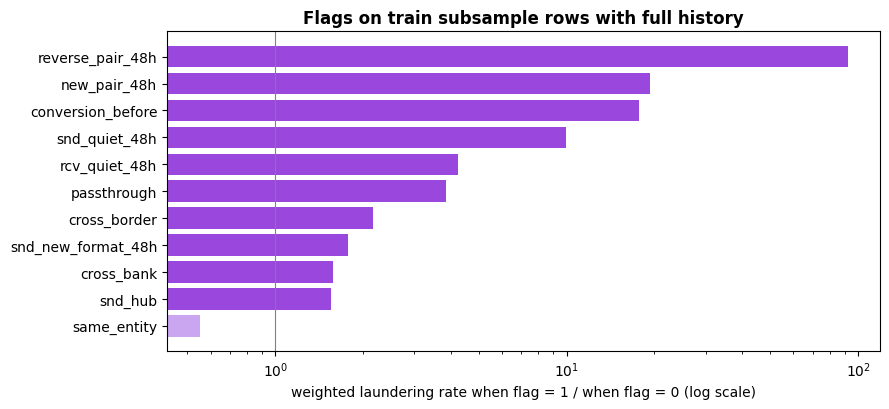

In [9]:
tr = feat_raw[(feat_raw["split"] == "train") & feat_raw["history_complete"]]
w, y = tr["weight"].to_numpy(), tr[TARGET].to_numpy()
rows = {}
for f in FLAG_FEATURES:
    on = tr[f].to_numpy() == 1
    r_on = (w * y)[on].sum() / w[on].sum() if w[on].sum() else 0.0
    r_off = (w * y)[~on].sum() / w[~on].sum() if w[~on].sum() else 0.0
    rows[f] = {"share of rows % (weighted)": 100 * w[on].sum() / w.sum(),
               "rate when 1 %": 100 * r_on, "rate when 0 %": 100 * r_off}
lift = pd.DataFrame(rows).T
lift["ratio"] = (lift["rate when 1 %"] / lift["rate when 0 %"]).round(2)
display(lift.round(4).sort_values("ratio", ascending=False))

num = COUNT_FEATURES + TIME_FEATURES + AMOUNT_FEATURES
med = pd.DataFrame({cls: [wquantile(tr.loc[y == k, f_], w[y == k], 0.5) for f_ in num]
                    for cls, k in [("normal (weighted median)", 0), ("laundering (median)", 1)]}, index=num)
display(med)

fig, ax = plt.subplots(figsize=(9, 4.2))
lr = lift["ratio"].replace([np.inf, -np.inf], np.nan).dropna()
lr = lr[lr > 0].sort_values()
ax.barh(lr.index, lr.values, color=[PURPLE if v >= 1 else LILAC for v in lr.values])
ax.axvline(1, color="grey", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("weighted laundering rate when flag = 1 / when flag = 0 (log scale)")
ax.set_title("Flags on train subsample rows with full history", fontweight="bold")
plt.tight_layout()
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(REPORTS / "figures" / "03_flag_lift_train.png", dpi=150)
plt.show()

### <span style="color:#9947dc">4.2 Why the history comes from the full file</span>

**Why.** EDA B6 showed that account counts computed **inside the sample** are wrong for most
rows, because only seed accounts have their full history there. This recomputes three of our
features from the subsample alone and compares them with the full-file version, by class.

**What to look for.** Pair features should agree 100% (every subsample row has a seed on one side,
and a seed's history contains every earlier transfer of that pair). Account counts should agree far
less often for **normal** rows than for **laundering** rows: computed from the sample, the error would
depend on the label, which a model would learn. That is why `HISTORY_FROM = "full"`.

In [10]:
if HISTORY_FROM == "full":
    sh = sample_ids.loc[~sample_ids["is_self"], "row_id"].to_numpy() - 1      # sample rows as the only history
    sa, sb, st = base["af"].to_numpy()[sh], base["at"].to_numpy()[sh], base["t"].to_numpy()[sh]
    q = feat_raw[feat_raw["history_complete"]]
    pos = q["row_id"].to_numpy() - 1
    qa, qb, qt = base["af"].to_numpy()[pos], base["at"].to_numpy()[pos], base["t"].to_numpy()[pos]
    n = int(max(base["af"].max(), base["at"].max())) + 1
    x = pd.DataFrame({
        "rows": np.where(q[TARGET].to_numpy() == 1, "laundering", "normal"),
        "full_snd": q["snd_sent_48h"].to_numpy(), "full_rcv": q["rcv_recv_48h"].to_numpy(),
        "full_pair": q["pair_prev_48h"].to_numpy(),
        "s_snd": count_in_window(sa, st, qa, qt - H48, qt),
        "s_rcv": count_in_window(sb, st, qb, qt - H48, qt),
        "s_pair": count_in_window(sa * n + sb, st, qa * n + qb, qt - H48, qt),
    })
    x["snd_same"], x["rcv_same"], x["pair_same"] = (x["s_snd"] == x["full_snd"]), (x["s_rcv"] == x["full_rcv"]), \
        (x["s_pair"] == x["full_pair"])
    cmp = x.groupby("rows").agg(snd_sent_48h_same_pct=("snd_same", "mean"), rcv_recv_48h_same_pct=("rcv_same", "mean"),
                                pair_prev_48h_same_pct=("pair_same", "mean"),
                                snd_sent_48h_median_full=("full_snd", "median"),
                                snd_sent_48h_median_sample=("s_snd", "median")).reset_index()
    cmp[["snd_sent_48h_same_pct", "rcv_recv_48h_same_pct", "pair_prev_48h_same_pct"]] *= 100
    display(cmp.round(2))
    del x, sh, q
else:
    print("HISTORY_FROM = 'sample': nothing to compare.")

,rows,snd_sent_48h_same_pct,rcv_recv_48h_same_pct,pair_prev_48h_same_pct,snd_sent_48h_median_full,snd_sent_48h_median_sample
0,laundering,88.45,100.00,100.0,2.0,2.0
1,normal,65.37,80.07,100.0,8.0,5.0


## <span style="color:#9947dc">5. Fit on train: caps and category levels</span>

**Why.**
- **Caps (EDA B12).** Hub accounts produce counts thousands of times above a normal account. Trees do
  not care; logistic regression and any scaling would. Each count is capped at its **weighted train
  99.9th percentile** (never below 1); the same cap applies to val and test.
- **Rare categories.** Levels with less than a minimum **weighted** train volume become `"Other"`;
  levels never seen in train map to `"Other"` in val / test.

Both use the subsample weights, so a threshold means "real transfers", not "subsample rows".

In [11]:
def step_fit(feat_raw, log) -> tuple:
    tr = feat_raw[feat_raw["split"] == "train"]
    trc = tr[tr["history_complete"]]
    caps = {}
    for f in COUNT_FEATURES:
        v = wquantile(trc[f], trc["weight"], CAP_QUANTILE)
        caps[f] = int(max(v or 0, 1))
    levels = {}
    for c, k in CATEGORY_MIN_WEIGHT.items():
        vol = tr.groupby(c)["weight"].sum()
        levels[c] = sorted(lv for lv in vol.index[vol >= k] if lv != "Other")
    feat = feat_raw.copy()
    n_capped = {f: int((feat_raw[f] > caps[f]).sum()) for f in COUNT_FEATURES}
    for f in COUNT_FEATURES:
        feat[f] = np.minimum(feat[f], caps[f]).astype(np.int32)
    for c in CATEGORICAL_FEATURES:
        feat[c] = feat[c].where(feat[c].isin(levels[c]), "Other")
    log("caps and category levels fitted on the train split")
    return feat, caps, levels, n_capped


log("5. caps and category levels from train")
feat, caps, levels, n_capped = step_fit(feat_raw, log)
display(pd.DataFrame({"cap (weighted train 99.9th pct)": caps, "rows above cap (all splits)": n_capped}))
display(pd.DataFrame({"levels kept": {c: len(v) for c, v in levels.items()},
                      "min weighted train volume": CATEGORY_MIN_WEIGHT}))

[ 205.4s] 5. caps and category levels from train
[ 207.0s] caps and category levels fitted on the train split


,cap (weighted train 99.9th pct),rows above cap (all splits)
snd_sent_48h,44690,570
snd_recv_48h,543,18
rcv_recv_48h,45,1147
rcv_sent_48h,35,1659
snd_cpty_48h,13255,879
rcv_cpty_48h,45,1144
pair_prev_48h,14,6
snd_sent_24h,22706,1857
snd_sent_60m,841,6573
rcv_recv_24h,45,1090


,levels kept,min weighted train volume
payment_format,6,100
payment_currency,15,100
country_from,30,100
country_to,31,100
etype_from,6,100
etype_to,5,100


## <span style="color:#9947dc">6. Export</span>

Per split, a **features** file (row_id, the 40 features, the label) and a **meta** file (row_id,
`weight`, timestamp, account keys, splits, `history_complete`, `seed_from` / `seed_to` for the agent,
amount in USD, and ground truth `explained` / `Attempt ID` / `Pattern Type` — evaluation only). Plus
`artifacts.json` with everything learned from train, so new transfers can be transformed the same way.

**For modelling** (EDA B4, B19):
- pass `sample_weight = weight` to every metric (and to fitting, if the model uses it);
- fit on `history_complete` rows; cast categoricals with `artifacts.json` → `category_levels` + `"Other"`;
- report test metrics on rows dated 8–10 Sept (`own_date_split == "test"`); moved scheme rows belong in the scheme view;
- thresholds by alert volume, not a probability chosen on validation (test prevalence ≈ 2.7× train, B4).

In [12]:
def step_export(feat, out: Path) -> dict:
    out.mkdir(parents=True, exist_ok=True)
    counts = {}
    for name in SPLIT_DAYS:
        d = feat[feat["split"] == name].sort_values("row_id")
        d[["row_id"] + FEATURES + [TARGET]].to_parquet(out / f"{name}_features.parquet", index=False)
        meta = pa.Table.from_pandas(d[META_COLUMNS], preserve_index=False)
        pq.write_table(meta.replace_schema_metadata(None), out / f"{name}_meta.parquet")   # plain parquet types
        y, w, hc = d[TARGET].to_numpy(), d["weight"].to_numpy(), d["history_complete"].to_numpy()
        g = feat[feat["group_split"] == name]
        counts[name] = {
            "days": "{} to {}".format(*SPLIT_DAYS[name]),
            "rows": len(d), "positives": int(y.sum()),
            "weighted_rows": round(float(w.sum()), 1),
            "weighted_prevalence_pct": round(100 * float((w * y).sum()) / float(w.sum()), 4),
            "rows_history_complete": int(hc.sum()), "positives_history_complete": int(y[hc].sum()),
            "explained_positives": int(d["explained"].sum()), "attempts": int(d["Attempt ID"].nunique()),
            "attempts_truncated": int(d.loc[d["scheme_truncated"], "Attempt ID"].nunique()),
            "rows_moved_in": int(d["scheme_moved"].sum()),
            "group_split_rows": len(g), "group_split_positives": int(g[TARGET].sum()),
        }
    return counts


log("6. export")
counts = step_export(feat, OUT)
fx.to_csv(OUT / "fx_table.csv", index=False)
hubs.to_csv(OUT / "hubs.csv", index=False)
artifacts = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "source": JOINED.name, "sample_dir": "data/processed/sample/{time,group}", "pandas": pd.__version__,
    "settings": {"history_from": HISTORY_FROM, "cutoff": CUTOFF, "split_days": SPLIT_DAYS, "train_end": TRAIN_END,
                 "lookback_h": LOOKBACK_H, "passthrough_h": PASSTHROUGH_H, "passthrough_tol": PASSTHROUGH_TOL,
                 "hub_min_counterparties": HUB_MIN_COUNTERPARTIES, "conversion_rel_tol": CONVERSION_REL_TOL,
                 "cap_quantile": CAP_QUANTILE, "category_min_weight": CATEGORY_MIN_WEIGHT},
    "features": FEATURES,
    "feature_groups": {"count": COUNT_FEATURES, "time": TIME_FEATURES, "flag": FLAG_FEATURES,
                       "amount": AMOUNT_FEATURES, "categorical": CATEGORICAL_FEATURES,
                       "format": FORMAT_FEATURES, "generator": GENERATOR_FEATURES},
    "target": TARGET, "weight": "weight", "meta_columns": META_COLUMNS, "leak_columns": LEAK_COLUMNS,
    "caps": caps, "category_levels": levels,
    "fx_units_per_usd": dict(zip(fx["currency"], fx["units_per_usd"])), "fx_max_pair_spread": fx_spread,
    "hubs": hubs["acct"].tolist(),
}
(OUT / "artifacts.json").write_text(json.dumps(artifacts, indent=2, default=str), encoding="utf-8")
display(pd.DataFrame(counts).T)

[ 207.1s] 6. export


,days,rows,positives,weighted_rows,weighted_prevalence_pct,rows_history_complete,positives_history_complete,explained_positives,attempts,attempts_truncated,rows_moved_in,group_split_rows,group_split_positives
train,2022-09-01 to 2022-09-06,419472,1989,2685617.5,0.0741,211415,1277,771,124,0,0,495765,3157
val,2022-09-07 to 2022-09-07,73848,323,471786.1,0.0685,73848,323,155,31,1,94,104092,674
test,2022-09-08 to 2022-09-10,206026,2202,1312002.8,0.1678,206009,2185,1620,208,101,709,99489,683


### <span style="color:#9947dc">6.1 Drift between splits</span>

**Why.** The model trains on 1–6 Sept and is judged on 8–10 Sept (EDA B18 checks the signals day by
day). PSI compares each numeric feature's weighted val and test distribution with train, on rows
with full history, using weighted train deciles. Below 0.1 stable, 0.1–0.25 moderate, above 0.25
large. Count drift that follows daily volume can be tested in modelling with the `net_*` meta columns.

In [13]:
def psi_table(feat) -> pd.DataFrame:
    num = COUNT_FEATURES + TIME_FEATURES + AMOUNT_FEATURES
    frames = {s: feat.loc[(feat["split"] == s) & feat["history_complete"], ["weight"] + num] for s in SPLIT_DAYS}
    rows = []
    for f in num:
        tr = frames["train"].sort_values(f)
        cw = tr["weight"].cumsum().to_numpy() / tr["weight"].sum()
        edges = np.unique([tr[f].to_numpy()[np.searchsorted(cw, q)] for q in np.linspace(0.1, 0.9, 9)])
        edges = np.concatenate([[-np.inf], edges, [np.inf]])

        def dist(df):
            h = np.histogram(df[f].to_numpy(dtype=float), bins=edges, weights=df["weight"].to_numpy())[0]
            return np.clip(h / max(h.sum(), 1e-12), 1e-6, None)

        p = dist(frames["train"])
        row = {"feature": f}
        for s in ("val", "test"):
            qd = dist(frames[s])
            row[f"psi_{s}"] = round(float(np.sum((qd - p) * np.log(qd / p))), 4)
        rows.append(row)
    return pd.DataFrame(rows)


psi = psi_table(feat)
display(psi.set_index("feature").style.format("{:.4f}").background_gradient(cmap="Purples", vmin=0, vmax=0.5))

,psi_val,psi_test
feature,,
snd_sent_48h,0.1306,0.0845
snd_recv_48h,0.0714,0.1126
rcv_recv_48h,0.3049,0.1414
rcv_sent_48h,0.0481,0.0356
snd_cpty_48h,0.0454,0.0191
rcv_cpty_48h,0.1524,0.0233
pair_prev_48h,0.2948,0.0776
snd_sent_24h,0.0486,0.0330
snd_sent_60m,0.0013,0.0018


## <span style="color:#9947dc">7. Checks and data dictionary</span>

Every subsample row matched once; scored rows = subsample rows minus self-transfers; laundering rows
reconcile; no missing values; no leak / ID column among the features (EDA B3); split and weight
equal the subsample's; every attempt in one time split and one group split; moved rows only go to a
later split; caps hold everywhere; val / test categories are train levels or `"Other"`.

In [14]:
def run_checks(feat, info, caps, levels) -> list:
    checks = []

    def check(name, ok, detail=""):
        checks.append((name, bool(ok), detail))

    check("every subsample row matched exactly once", info["matched"] == info["sample_rows"] == info["matched_distinct"],
          f"{info['matched']:,} of {info['sample_rows']:,}")
    check("scored rows = subsample rows minus self-transfers", len(feat) == info["scored_rows"],
          f"{len(feat):,} vs {info['scored_rows']:,}")
    pos = int(feat[TARGET].sum())
    check("laundering rows reconcile (scored + self = subsample)",
          pos + info["sample_self_positives"] == info["sample_positives"],
          f"{pos:,} + {info['sample_self_positives']} vs {info['sample_positives']:,}")
    check("the subsample holds every laundering row of 1-10 Sept",
          info["sample_positives"] == info["full_positives_kept"],
          f"{info['sample_positives']:,} vs {info['full_positives_kept']:,}")
    check("no row on or after the cutoff", int((feat["Timestamp"] >= pd.Timestamp(CUTOFF)).sum()) == 0)
    check("no duplicate row keys in the full file", info["duplicate_row_keys"] == 0)
    nulls = int(feat[FEATURES].isna().any(axis=1).sum())
    check("no missing value in any feature", nulls == 0, f"{nulls} rows")
    check("no leak / ID column among the features", not set(FEATURES) & set(LEAK_COLUMNS))
    check("weights >= 1, laundering rows weight 1",
          int(((feat["weight"] < 1) | ((feat[TARGET] == 1) & (feat["weight"] != 1))).sum()) == 0)
    sch = feat[feat["Attempt ID"].notna()]
    check("each attempt in exactly one time split", int((sch.groupby("Attempt ID")["split"].nunique() > 1).sum()) == 0)
    check("each attempt in exactly one group split",
          int((sch.groupby("Attempt ID")["group_split"].nunique() > 1).sum()) == 0)
    check("non-scheme rows are in the split of their own date",
          int((feat["Attempt ID"].isna() & (feat["split"] != feat["own_date_split"])).sum()) == 0)
    later = (((feat["own_date_split"] == "train") & feat["split"].isin(["val", "test"]))
             | ((feat["own_date_split"] == "val") & (feat["split"] == "test")))
    check("moved rows only go to a LATER split", int((feat["scheme_moved"] & ~later).sum()) == 0)
    over = sum(int((feat[f] > caps[f]).sum()) for f in caps)
    check("caps applied in every split", over == 0, f"{over} values above cap")
    bad = sum(int(((feat[c] != "Other") & ~feat[c].isin(levels[c])).sum()) for c in CATEGORICAL_FEATURES)
    check("val / test categories are train levels or 'Other'", bad == 0, f"{bad} rows")
    return checks


def write_dictionary(path: Path, caps, levels, report) -> None:
    L = ["# Data dictionary - 03_PREPROCESSING.ipynb", "",
         "Rows: the subsample from 02_subsample_split.py (time split), self-transfers removed. Account history: "
         + ("the FULL joined file" if HISTORY_FROM == "full" else "the SUBSAMPLE")
         + ", transfers at strictly earlier timestamps. Section references are to EDA_HI_Small_v2 (A = full file, B = subsample).", "",
         "## Features", "", "| # | Feature | Type | How computed | EDA | Fitted on train |", "|---|---|---|---|---|---|"]
    kinds = ([("count", f) for f in COUNT_FEATURES] + [("time", f) for f in TIME_FEATURES] +
             [("flag", f) for f in FLAG_FEATURES] + [("numeric", f) for f in AMOUNT_FEATURES] +
             [("category", f) for f in CATEGORICAL_FEATURES])
    for i, (kind, f) in enumerate(kinds, 1):
        how, eda = DICTIONARY[f]
        fit = (f"cap {caps[f]:,}" if f in caps else f"{len(levels[f])} levels + Other" if f in levels
               else "hub list" if f.endswith("_hub") else "FX table" if f == "log_amount_usd" else "")
        L.append(f"| {i} | `{f}` | {kind} | {how} | {eda} | {fit} |")
    L += ["", "Generator artefacts (train with and without, EDA B8 / B15): `payment_format`, `conversion_before`.",
          "", "## Decisions", ""] + [f"- **{a}** - {b}" for a, b in DECISIONS]
    L += ["", "## Not built", ""] + [f"- **{k}** - {v}" for k, v in EXCLUDED.items()]
    L += ["", "## Meta columns (never features)", "", ", ".join(f"`{c}`" for c in META_COLUMNS) + ".", "",
          "Use `weight` as sample_weight in every metric (EDA B2). `explained`, `Attempt ID`, `Pattern Type` are "
          "ground truth. `seed_from` / `seed_to` = full history of that account is in the subsample (agent tools). "
          "`history_complete = False` = first 48 h, leave out of fitting.", "",
          "## Split sizes", "",
          "| Split | Days | Rows | Laundering | Weighted prevalence | Rows with full history | Attempts | Truncated |",
          "|---|---|---|---|---|---|---|---|"]
    for s, c in report["splits"].items():
        L.append(f"| {s} | {c['days']} | {c['rows']:,} | {c['positives']:,} | {c['weighted_prevalence_pct']}% | "
                 f"{c['rows_history_complete']:,} | {c['attempts']} | {c['attempts_truncated']} |")
    path.write_text("\n".join(L) + "\n", encoding="utf-8")


checks = run_checks(feat, info, caps, levels)
report = {"inputs": info, "splits": counts, "rows_capped": n_capped, "psi": psi.to_dict(orient="records"),
          "checks": [{"check": n, "passed": ok, "detail": d} for n, ok, d in checks]}
(OUT / "build_report.json").write_text(json.dumps(report, indent=2, default=str), encoding="utf-8")
write_dictionary(OUT / "data_dictionary.md", caps, levels, report)
for n, ok, d in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {n}" + (f"  ({d})" if d else ""))
n_ok = sum(ok for _, ok, _ in checks)
print(f"\n{n_ok} / {len(checks)} checks passed")
log(f"done -> {OUT}")
assert n_ok == len(checks), "a preprocessing check failed - do not use these files"

[PASS] every subsample row matched exactly once  (750,045 of 750,045)
[PASS] scored rows = subsample rows minus self-transfers  (699,346 vs 699,346)
[PASS] laundering rows reconcile (scored + self = subsample)  (4,514 + 8 vs 4,522)
[PASS] the subsample holds every laundering row of 1-10 Sept  (4,522 vs 4,522)
[PASS] no row on or after the cutoff
[PASS] no duplicate row keys in the full file
[PASS] no missing value in any feature  (0 rows)
[PASS] no leak / ID column among the features
[PASS] weights >= 1, laundering rows weight 1
[PASS] each attempt in exactly one time split
[PASS] each attempt in exactly one group split
[PASS] non-scheme rows are in the split of their own date
[PASS] moved rows only go to a LATER split
[PASS] caps applied in every split  (0 values above cap)
[PASS] val / test categories are train levels or 'Other'  (0 rows)

15 / 15 checks passed
[ 218.3s] done -> d:\capstone\aml_pipeline\data\processed\preprocessed


## <span style="color:#9947dc">8. Independent verification</span>

**Why.** The checks above come from the code that built the files, so they share its mistakes.
`03b_verify_preprocessing.py` shares no code with this notebook. It
re-numbers the full file, re-matches every subsample row, re-derives the splits, weights, FX table,
hub list, weighted caps and category levels, and recomputes **every feature** by brute force from
strictly earlier rows of the history source, for `VERIFY_ROWS` random rows plus 300 laundering rows
plus 100 rows where each flag is 1, so rare cases are always covered. It was tested by breaking this
notebook on purpose: same-minute leaks, history silently taken from the sample, self-transfers keyed
on account number only, hubs or caps fitted on all days, weights dropped, the wrong group split, and
an unwindowed reverse pair. Each break made it fail.

**What to look for.** The last line must read `N / N checks passed`. Needs about 4 GB of RAM, so
the big tables are freed first.

In [15]:
for _name in ("base", "feat_raw"):   # free memory for the verifier (it loads the full file itself); safe to re-run
    globals().pop(_name, None)
import gc; gc.collect()
if RUN_VERIFY:
    cmd = [sys.executable, str(ROOT / "src" / "03b_verify_preprocessing.py"), "--rows", str(VERIFY_ROWS)]
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, cwd=ROOT,
                            encoding="utf-8", errors="replace", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    lines = []
    for line in proc.stdout:
        print(line, end="")
        lines.append(line)
    proc.wait()
    last = lines[-1].strip() if lines else ""
    ok = proc.returncode == 0 and last.endswith("checks passed") and last.split(" / ")[0] == last.split(" / ")[1].split()[0]
    assert ok, f"verification failed (exit code {proc.returncode}): {last}"
else:
    print("RUN_VERIFY = False - skipped. Run `python src/03b_verify_preprocessing.py` before modelling.")

history source: full
loading the joined file ...
matching the subsample ...

A. rows
[PASS] every subsample row (time folder) found in the joined file exactly once  (750,045 rows)
[PASS] group folder holds the same rows
[PASS] the subsample holds every laundering row of the full file  (4,522)
[PASS] feature files have exactly row_id + features + target
[PASS] no leak / meta column among features
[PASS] no missing values in X
[PASS] features and meta files have the same rows
[PASS] scored rows = subsample rows minus self-transfers (bank AND account)  (699,346 vs 699,346)
[PASS] labels equal the raw rows' labels  (4,514 laundering rows)
[PASS] rows dropped = rows on or after the cutoff  (1,108)
[PASS] weight, seed_from, seed_to equal the subsample's
[PASS] meta account keys = '<bank id>:<account>' of the raw row

B. splits
[PASS] split = the subsample's time split
[PASS] own_date_split matches the row date
[PASS] split follows the rule: own date, or the date of the attempt's last row
[PA